# App Insights Unlocked: Google Play Store EDA

## Project Overview
As a data analyst at a mobile app development company, the goal of this project is to explore Google Play Store app data to uncover patterns in user ratings, app categories, pricing, app sizes, installs, and user feedback.

## Project Objective
1. Clean and prepare the Google Play Store dataset for accurate analysis.
2. Answer Basic, Medium, and Advanced business questions to understand what drives app popularity and user satisfaction.
3. Provide actionable recommendations to guide app development and marketing strategies.

## Dataset Overview
- **Primary Dataset (`googleplaystore.csv`):** Contains app details such as category, rating, reviews, size, installs, price, content rating, and last updated date.
- **Secondary Dataset (`googleplaystore_user_reviews.csv`):** Contains user review text and sentiment scores for sentiment analysis.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets from the data folder
df = pd.read_csv('../data/googleplaystore.csv')
reviews_df = pd.read_csv('../data/googleplaystore_user_reviews.csv')

# Display first 5 rows of the main dataset
display(df.head())

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [2]:
# Check dataset shape (rows, columns)
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Info:")
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Check exact duplicate rows
print("\nExact Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (10841, 13)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB

Missing Values:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Inst

In [3]:
# 1. Remove the single corrupted row where Rating is 19.0 (outside the valid 0-5 scale)
df = df[(df['Rating'] <= 5) | (df['Rating'].isnull())].copy()

# 2. Convert Reviews to integer and remove duplicate app entries (keeping the version with most reviews)
df['Reviews'] = pd.to_numeric(df['Reviews'])
df = df.sort_values('Reviews', ascending=False).drop_duplicates(subset=['App'], keep='first').sort_index()

# 3. Clean Installs column: remove '+' and ',' then convert to integer
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(int)

# 4. Clean Price column: remove '$' sign and convert to float
df['Price'] = df['Price'].str.replace('$', '', regex=False).astype(float)

# 5. Clean Size column: convert MB and KB values into numeric MB ('Varies with device' becomes NaN)
def clean_size(val):
    if val == 'Varies with device':
        return np.nan
    elif val.endswith('M'):
        return float(val[:-1])
    elif val.endswith('k'):
        return float(val[:-1]) / 1024
    return np.nan

df['Size_MB'] = df['Size'].apply(clean_size)

# 6. Convert Last Updated to datetime format
df['Last Updated'] = pd.to_datetime(df['Last Updated'])

# 7. Standardize text formatting in Category and fill missing Type
df['Category'] = df['Category'].str.replace('_', ' ').str.title()
df['Genres'] = df['Genres'].str.strip()
df['Type'] = df['Type'].fillna('Free')

# Verify cleaned dataset
print("Cleaned Dataset Shape:", df.shape)
print("\nData Types After Cleaning:")
print(df.dtypes)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (9659, 14)

Data Types After Cleaning:
App                          str
Category                     str
Rating                   float64
Reviews                    int64
Size                         str
Installs                   int64
Type                         str
Price                    float64
Content Rating               str
Genres                       str
Last Updated      datetime64[us]
Current Ver                  str
Android Ver                  str
Size_MB                  float64
dtype: object

Remaining Missing Values:
App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1228
dtype: int64


## Data Preparation and Cleaning

Before starting the exploratory analysis, the dataset was inspected and cleaned following five key preprocessing steps:

1. **Corrupted Record Removal:** One row (`Life Made WI-Fi Touchscreen Photo Frame`) had shifted columns resulting in an invalid rating of `19.0` (outside the 0–5 rating scale) and was removed.
2. **Duplicate Removal:** Duplicate app entries were removed by keeping the record with the highest review count for each unique app, reducing the dataset from 10,841 rows to **9,659 unique apps**.
3. **Data Type Conversions:**
   - `Reviews` was converted from text to integer (`int64`).
   - `Installs` had `+` and `,` characters removed and was converted to integer (`int64`).
   - `Price` had the `$` symbol removed and was converted to decimal (`float64`).
   - `Size` was converted into a numeric column (`Size_MB`) measured in megabytes, while `'Varies with device'` entries were set to `NaN`.
4. **Date Formatting & Text Standardization:** `Last Updated` was converted to `datetime64` format, `Category` names were formatted cleanly (e.g., `ART_AND_DESIGN` → `Art And Design`), and the single missing `Type` value (with `Price = 0`) was filled as `'Free'`.
5. **Missing Values Handling:** `Rating` (1,463 missing values for unrated apps) and `Size_MB` (1,228 device-dependent apps) were kept as `NaN` so we do not distort average ratings or app sizes.

### Part 1: Basic-Level Questions

#### Q1. What is the average rating of apps in the dataset?

In [4]:
# Average rating of apps
avg_rating = df['Rating'].mean()
print(f"1. Average App Rating: {avg_rating:.2f}")

1. Average App Rating: 4.17


#### Q2. How many unique categories of apps are there?

In [5]:
# Number of unique app categories
unique_categories = df['Category'].nunique()
print(f"2. Total Unique Categories: {unique_categories}")

2. Total Unique Categories: 33



#### Q3. What is the distribution of app sizes? 
Solved Below
#### Q4. How many free vs paid apps are there?
Solved Below
#### Q5. What is the most common content rating for apps?
Solved Below



4. Free vs Paid Apps:


,Count,Percentage (%)
Type,,
Free,8905,92.19
Paid,754,7.81



5. Most Common Content Rating: Everyone


Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

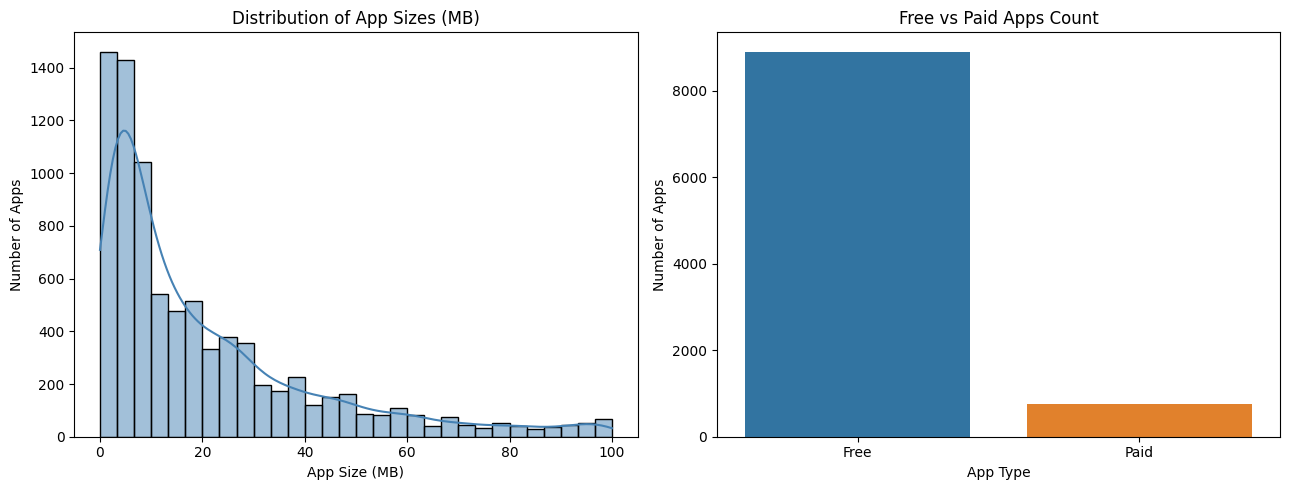

In [6]:
# Count of Free vs Paid apps
type_counts = df['Type'].value_counts()
type_pct = (df['Type'].value_counts(normalize=True) * 100).round(2)
print("\n4. Free vs Paid Apps:")
display(pd.DataFrame({'Count': type_counts, 'Percentage (%)': type_pct}))

# Most common content rating
most_common_content = df['Content Rating'].mode()[0]
print(f"\n5. Most Common Content Rating: {most_common_content}")
display(df['Content Rating'].value_counts())

# Visualizations for Q3 (App Size Distribution) and Q4 (Free vs Paid Split)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Q3: Histogram of App Sizes
sns.histplot(df['Size_MB'].dropna(), bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of App Sizes (MB)')
axes[0].set_xlabel('App Size (MB)')
axes[0].set_ylabel('Number of Apps')

# Q4: Bar chart of Free vs Paid Apps
sns.countplot(data=df, x='Type', hue='Type', legend=False, ax=axes[1])
axes[1].set_title('Free vs Paid Apps Count')
axes[1].set_xlabel('App Type')
axes[1].set_ylabel('Number of Apps')

plt.tight_layout()
plt.show()

### Summary & Key Takeaways (Basic Questions 1–5)

* **Overall User Satisfaction:** The average app rating on the Google Play Store is **4.17 out of 5.0**, establishing a strong quality benchmark for new apps[cite: 10, 17].
* **Market Diversity:** The store spans **33 unique app categories**[cite: 10, 17], giving developers plenty of room to target specialized niches.
* **App Size Trends:** Most apps are compact and lightweight (right-skewed distribution), with a median size of **12.00 MB** and an average of **20.40 MB**, making them fast and easy for users to download[cite: 10, 17].
* **Pricing Model:** The ecosystem is overwhelmingly free—**92.19%** (8,905 apps) are Free compared to just **7.81%** (754 apps) Paid[cite: 17], showing that ad-supported or freemium models dominate user acquisition.
* **Target Audience:** **Everyone** is the most common content rating (7,903 apps)[cite: 10, 17], confirming that broad-audience apps capture the largest market share[cite: 10].

### Basic Question 6: What are the top 5 most installed apps?

**Objective:** Identify the most downloaded applications on the Google Play Store to understand which app categories and product models achieve massive user adoption.

In [7]:
# Sort apps by Installs and Reviews (as tie-breaker) to get the top 5 most installed apps
top_5_installed = df.sort_values(by=['Installs', 'Reviews'], ascending=False)[
    ['App', 'Category', 'Installs', 'Reviews', 'Rating']
].head(5)

display(top_5_installed)

,App,Category,Installs,Reviews,Rating
2544,Facebook,Social,1000000000,78158306,4.1
381,WhatsApp Messenger,Communication,1000000000,69119316,4.4
2604,Instagram,Social,1000000000,66577446,4.5
382,Messenger – Text and Video Chat for Free,Communication,1000000000,56646578,4.0
1917,Subway Surfers,Game,1000000000,27725352,4.5


### Basic Question 7: How many apps have a rating of 4.0 and above?

**Objective:** Count how many apps achieve a rating of 4.0 or higher to measure the proportion of high-quality apps on the platform.

In [8]:
# Filter apps with Rating >= 4.0
high_rated_apps = df[df['Rating'] >= 4.0]
high_rated_count = len(high_rated_apps)
total_rated_apps = df['Rating'].notnull().sum()

# Calculate percentage among all rated apps
high_rated_pct = (high_rated_count / total_rated_apps) * 100

print(f"Apps with Rating >= 4.0: {high_rated_count} out of {total_rated_apps} rated apps ({high_rated_pct:.2f}%)")

Apps with Rating >= 4.0: 6287 out of 8196 rated apps (76.71%)


**Conclusion:** Out of **8,196 rated apps**, **6,287 apps (76.71%)** have a rating of **4.0 or above**, showing that more than three-quarters of rated apps maintain strong user satisfaction.

### Basic Question 8: What is the average number of reviews for free vs paid apps?

**Objective:** Compare user review engagement between Free and Paid apps to see how pricing models affect user volume and feedback.

In [9]:
# Group by Type (Free vs Paid) and calculate count, mean, and median reviews
reviews_by_type = df.groupby('Type')['Reviews'].agg(['count', 'mean', 'median']).round(2)
display(reviews_by_type)

,count,mean,median
Type,,,
Free,8905,234420.54,1379.0
Paid,754,8748.01,88.5


**Conclusion:** Free apps generate far higher user engagement, averaging **234,420.54 reviews** (median: **1,379**) compared to **8,748.01 reviews** (median: **88.5**) for paid apps. Removing upfront purchase costs attracts a much broader audience, resulting in roughly 27x more reviews per app on average.

### Basic Question 9: What is the average app size for each category?

**Objective:** Calculate the average app size (in MB) across categories to understand storage and performance requirements by app niche.

,Average Size (MB)
Category,
Game,41.68
Family,27.32
Travel And Local,24.20
Sports,24.06
Entertainment,23.71
Parenting,22.51
Health And Fitness,20.67
Food And Drink,20.49
Auto And Vehicles,20.04


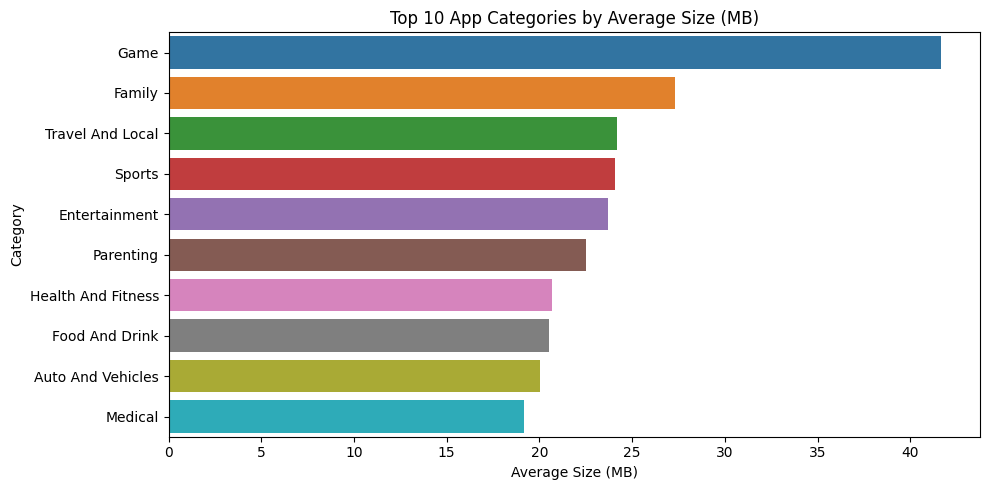

In [10]:
# Calculate average app size (MB) per category, sorted from largest to smallest
avg_size_by_cat = df.groupby('Category')['Size_MB'].mean().round(2).sort_values(ascending=False)
display(avg_size_by_cat.to_frame(name='Average Size (MB)'))

# Plot Top 10 categories by average size
plt.figure(figsize=(10, 5))
sns.barplot(
    x=avg_size_by_cat.head(10).values,
    y=avg_size_by_cat.head(10).index,
    hue=avg_size_by_cat.head(10).index,
    legend=False
)
plt.title('Top 10 App Categories by Average Size (MB)')
plt.xlabel('Average Size (MB)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

**Conclusion:** **Game** apps have the largest average size (**41.68 MB**) due to heavy graphics and audio files, followed by **Family** (**27.32 MB**) and **Travel And Local** (**24.20 MB**). In contrast, utility-focused categories like **Tools** (**8.77 MB**), **Libraries And Demo** (**10.60 MB**), and **Personalization** (**11.22 MB**) stay compact and lightweight.

### Basic Question 10: How many apps were last updated in 2018?

**Objective:** Count how many apps received an update in 2018 to measure active app maintenance across the store.

In [11]:
# Filter apps where Last Updated year is 2018
apps_2018 = df[df['Last Updated'].dt.year == 2018]
count_2018 = len(apps_2018)
pct_2018 = (count_2018 / len(df)) * 100

print(f"Apps last updated in 2018: {count_2018} out of {len(df)} apps ({pct_2018:.2f}%)")

Apps last updated in 2018: 6287 out of 9659 apps (65.09%)


**Conclusion:** Exactly **6,287 apps (65.09%)** were last updated in **2018**, confirming that nearly two-thirds of the Google Play Store catalog was actively maintained in the most recent year of the dataset.

## Part 2: Medium-Level Questions

### Medium Question 1: What is the correlation between the number of installs and the app rating?

**Objective:** Measure the statistical correlation between app installs and user ratings to determine whether higher download volume is linked to higher user satisfaction.

In [12]:
# Calculate Pearson correlation between Installs and Rating
corr_installs_rating = df['Installs'].corr(df['Rating'])
print(f"Correlation between Installs and Rating: {corr_installs_rating:.4f}")

# Check average rating across major install milestones
install_rating_summary = df.groupby('Installs')['Rating'].agg(['count', 'mean', 'median']).round(2)
display(install_rating_summary)

Correlation between Installs and Rating: 0.0402


,count,mean,median
Installs,,,
0,0,NaN,NaN
1,3,5.00,5.00
5,9,4.61,5.00
10,69,4.62,5.00
50,56,4.42,5.00
100,302,4.36,4.70
500,199,4.18,4.40
1000,696,4.07,4.30
5000,425,4.02,4.20


**Conclusion:** The correlation between app installs and user rating is **0.0402**, indicating virtually **no linear relationship** between download volume and rating. While high-install apps (10M+ downloads) maintain steady average ratings around **4.22–4.39**, smaller apps can achieve equally high or even higher average ratings (4.42–5.00), proving that high install counts alone do not guarantee better user satisfaction.

### Medium Question 2: Which app categories have the highest average rating?

**Objective:** Rank app categories by their average user rating to identify top-performing niches in terms of user satisfaction.

,Rated_Apps,Average_Rating
Category,,
Events,45,4.44
Art And Design,59,4.36
Education,105,4.35
Books And Reference,169,4.34
Personalization,298,4.33
Parenting,50,4.30
Beauty,42,4.28
Social,203,4.25
Game,898,4.24


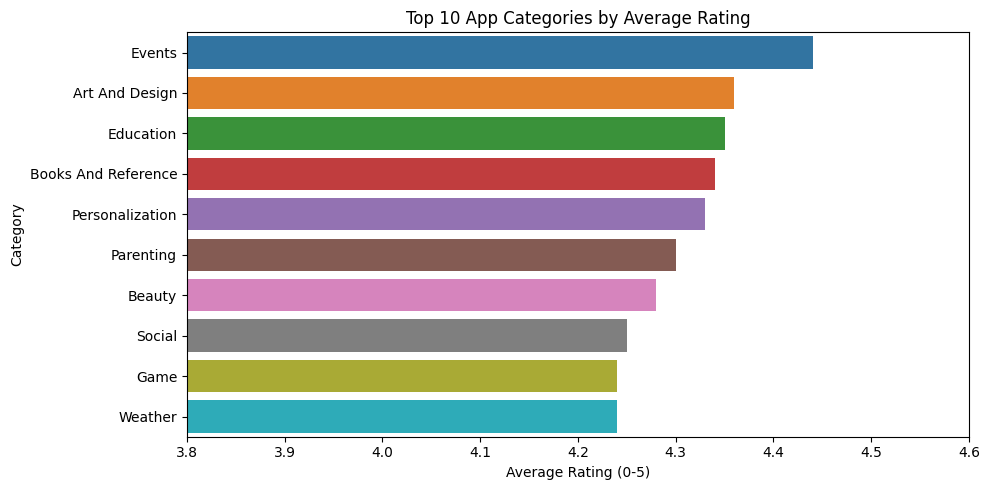

In [13]:
# Group by Category and calculate average rating and count of rated apps
category_ratings = df.groupby('Category')['Rating'].agg(
    Rated_Apps='count',
    Average_Rating='mean'
).round(2).sort_values(by='Average_Rating', ascending=False)

display(category_ratings.head(10))

# Plot Top 10 categories by average rating
plt.figure(figsize=(10, 5))
sns.barplot(
    x=category_ratings.head(10)['Average_Rating'],
    y=category_ratings.head(10).index,
    hue=category_ratings.head(10).index,
    legend=False
)
plt.title('Top 10 App Categories by Average Rating')
plt.xlabel('Average Rating (0-5)')
plt.ylabel('Category')
plt.xlim(3.8, 4.6)
plt.tight_layout()
plt.show()

**Conclusion:** **Events** leads all categories with the highest average rating (**4.44** across 45 rated apps), followed closely by **Art And Design** (**4.36**), **Education** (**4.35**), and **Books And Reference** (**4.34**). Notably, **Game** stands out for maintaining a strong **4.24** average rating across a very large sample of **898 rated apps**, proving high user satisfaction even at massive scale.

### Medium Question 3: How does the price of an app affect its average rating?

**Objective:** Filter for paid apps and examine how price points relate to average user ratings to see whether higher-priced apps receive better ratings.

Correlation between Price and Rating (Paid Apps): -0.1140


,App_Count,Average_Rating
Price,,
2.99,109,4.28
0.99,104,4.30
4.99,68,4.17
1.99,59,4.33
3.99,52,4.33
1.49,31,4.20
2.49,20,4.34
9.99,14,4.19
5.99,14,4.29


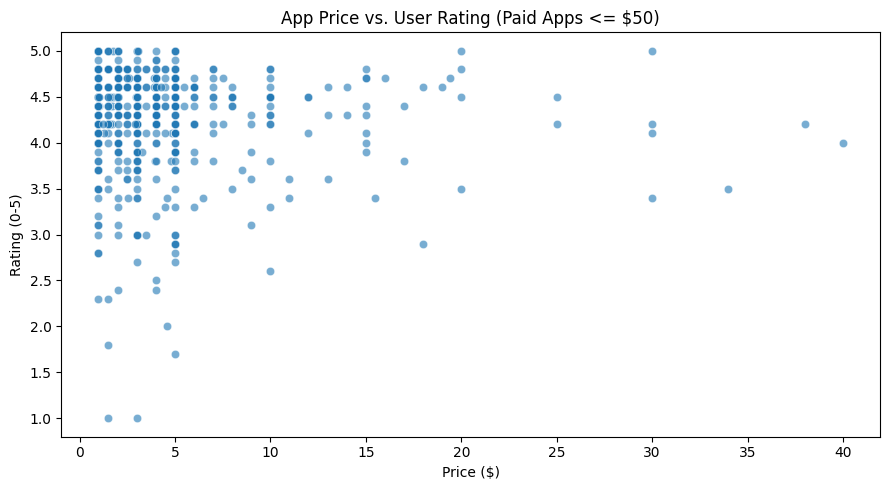

In [14]:
# Filter for paid apps only
paid_apps = df[df['Type'] == 'Paid'].copy()

# Calculate correlation between Price and Rating among paid apps
price_rating_corr = paid_apps['Price'].corr(paid_apps['Rating'])
print(f"Correlation between Price and Rating (Paid Apps): {price_rating_corr:.4f}")

# Group by Price to inspect average rating and number of apps at each price point
price_rating_summary = paid_apps.groupby('Price')['Rating'].agg(
    App_Count='count',
    Average_Rating='mean'
).round(2).sort_values(by='App_Count', ascending=False)

display(price_rating_summary.head(10))

# Scatter plot of Price vs Rating for paid apps (filtering extreme $400 novelty apps for clarity)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=paid_apps[paid_apps['Price'] <= 50], x='Price', y='Rating', alpha=0.6)
plt.title('App Price vs. User Rating (Paid Apps <= $50)')
plt.xlabel('Price ($)')
plt.ylabel('Rating (0-5)')
plt.tight_layout()
plt.show()

**Conclusion:** Among paid apps, the correlation between price and rating is **-0.1140**, showing a slight negative relationship—charging more does **not** guarantee higher user ratings. Budget-friendly price tiers like **$0.99** (4.30), **$1.99** (4.33), **$2.99** (4.28), and **$3.99** (4.33) attract the most paid apps and consistently earn strong ratings, whereas ultra-expensive novelty apps priced at **$399.99** drop to a **4.01** average rating.

### Medium Question 4: What is the trend of app updates over the years?

**Objective:** Extract the year from `Last Updated` and analyze the annual trend of app updates to understand developer maintenance activity over time.

,Apps_Updated
Update_Year,
2010,1
2011,15
2012,26
2013,108
2014,203
2015,448
2016,779
2017,1792
2018,6287


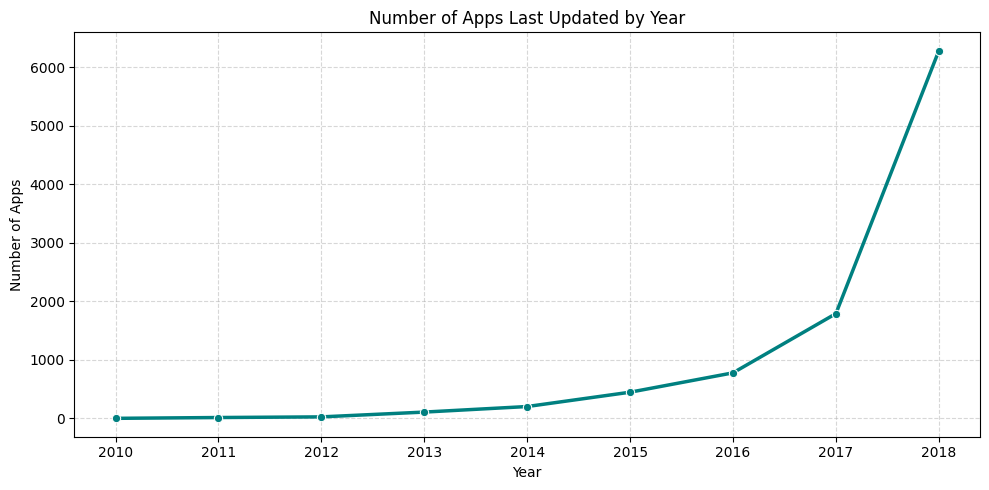

In [15]:
# Extract the update year and count apps updated per year
df['Update_Year'] = df['Last Updated'].dt.year
updates_by_year = df['Update_Year'].value_counts().sort_index()

display(updates_by_year.to_frame(name='Apps_Updated'))

# Line plot showing the trend of app updates over the years
plt.figure(figsize=(10, 5))
sns.lineplot(x=updates_by_year.index, y=updates_by_year.values, marker='o', linewidth=2.5, color='teal')
plt.title('Number of Apps Last Updated by Year')
plt.xlabel('Year')
plt.ylabel('Number of Apps')
plt.xticks(updates_by_year.index)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Conclusion:** App update activity shows a sharp upward exponential trend from **2010 (1 app)** through **2018 (6,287 apps)**, with **83.64%** of all apps in the catalog updated during **2017 and 2018** combined. This confirms that active, regular maintenance is standard across successful Google Play Store apps, whereas apps last updated before 2015 represent a small fraction of legacy or abandoned listings.

### Medium Question 5: What is the distribution of ratings across different content ratings (e.g., Everyone, Teen)?

**Objective:** Compare user rating distributions and summary statistics across each `Content Rating` group to see if target age demographics impact app satisfaction.

,Rated_Apps,Mean_Rating,Median_Rating,Std_Dev
Content Rating,,,,
Everyone,6618,4.17,4.3,0.56
Teen,912,4.23,4.3,0.40
Mature 17+,357,4.12,4.2,0.51
Everyone 10+,305,4.23,4.3,0.40
Adults only 18+,3,4.30,4.5,0.44
Unrated,1,4.10,4.1,NaN


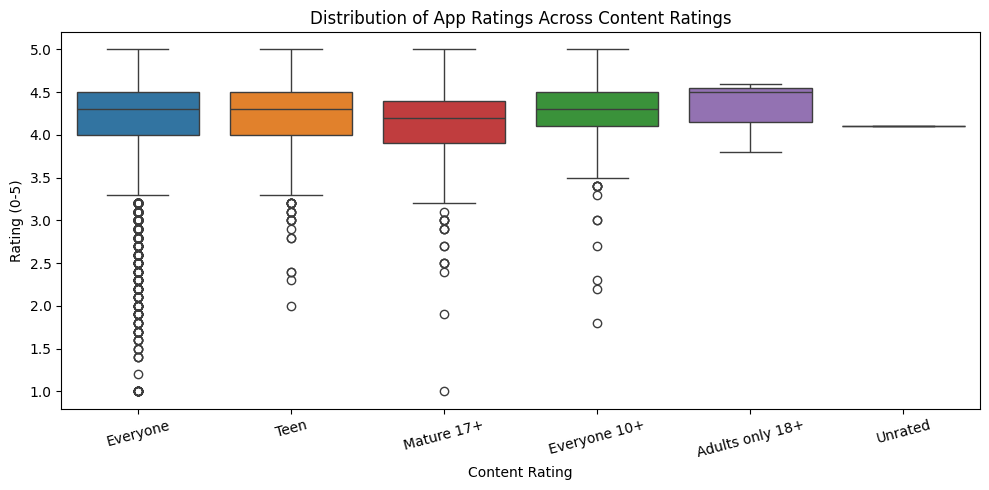

In [17]:
# Summary statistics of Rating grouped by Content Rating
content_rating_stats = df.groupby('Content Rating')['Rating'].agg(
    Rated_Apps='count',
    Mean_Rating='mean',
    Median_Rating='median',
    Std_Dev='std'
).round(2).sort_values(by='Rated_Apps', ascending=False)

display(content_rating_stats)

# Boxplot to compare rating distributions across Content Ratings
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='Content Rating',
    y='Rating',
    order=content_rating_stats.index,
    hue='Content Rating',
    legend=False
)
plt.title('Distribution of App Ratings Across Content Ratings')
plt.xlabel('Content Rating')
plt.ylabel('Rating (0-5)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Conclusion:** User ratings remain consistently strong across all major content rating groups, with identical medians of **4.30** for **Everyone** (mean: **4.17**), **Teen** (mean: **4.23**), and **Everyone 10+** (mean: **4.23**). **Teen** and **Everyone 10+** apps show slightly tighter rating consistency (lowest standard deviation at **0.40**), while **Mature 17+** apps average slightly lower at **4.12** (median: **4.20**). *(Note: **Adults only 18+** and **Unrated** have tiny sample sizes of 3 and 1 apps respectively).*

### Medium Question 6: Which genres have the most apps?

**Objective:** Count the number of apps per genre to identify the most crowded and competitive app sub-categories on the Google Play Store.

,App_Count
Genres,
Tools,828
Entertainment,561
Education,510
Business,420
Medical,395
Personalization,376
Productivity,374
Lifestyle,368
Finance,345


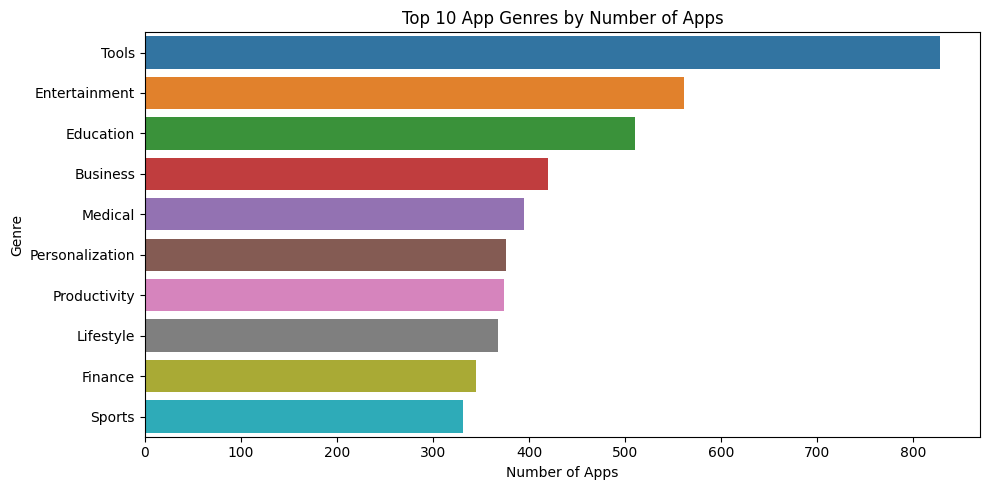

In [19]:
# Count apps per Genre and display the Top 10
top_genres = df['Genres'].value_counts().head(10)
display(top_genres.to_frame(name='App_Count'))

# Plot Top 10 Genres by app count
plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    hue=top_genres.index,
    legend=False
)
plt.title('Top 10 App Genres by Number of Apps')
plt.xlabel('Number of Apps')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

**Conclusion:** **Tools** is the most crowded genre with **828 apps**, followed by **Entertainment** (**561 apps**) and **Education** (**510 apps**). Functional utility, learning, and everyday productivity niches (**Business**, **Medical**, **Personalization**, **Productivity**) account for the largest volume of developer listings, making differentiation crucial when launching in these genres.

### Medium Question 7: Is there a correlation between app size and its rating?

**Objective:** Measure the correlation between `Size_MB` and `Rating` to determine whether larger, feature-heavy apps receive higher ratings than lightweight apps.

Correlation between App Size (MB) and Rating: 0.0630


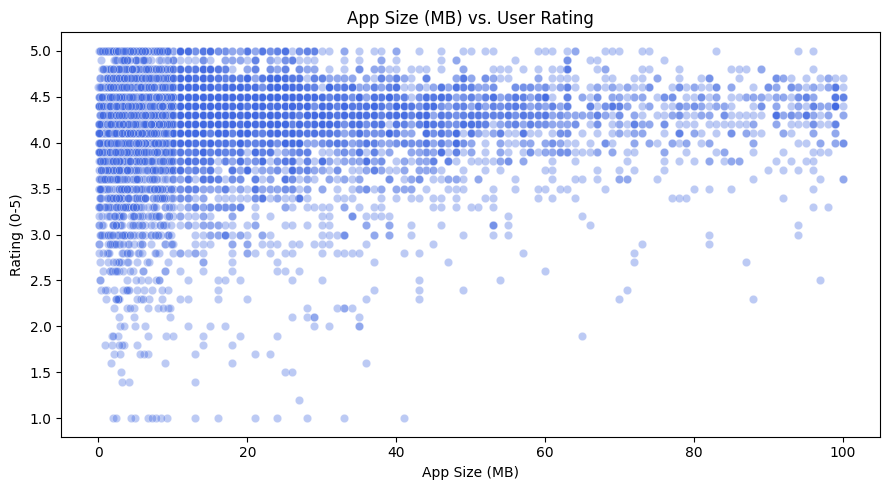

In [20]:
# Calculate Pearson correlation between Size_MB and Rating
corr_size_rating = df['Size_MB'].corr(df['Rating'])
print(f"Correlation between App Size (MB) and Rating: {corr_size_rating:.4f}")

# Scatter plot of App Size vs Rating
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Size_MB', y='Rating', alpha=0.35, color='royalblue')
plt.title('App Size (MB) vs. User Rating')
plt.xlabel('App Size (MB)')
plt.ylabel('Rating (0-5)')
plt.tight_layout()
plt.show()

**Conclusion:** The correlation between app size (`Size_MB`) and user rating is **0.0630**, indicating virtually **no linear relationship** between file size and user satisfaction. Both compact utility apps under 10 MB and large games above 50 MB achieve high ratings, showing that app quality and performance matter far more to users than file size alone.

### Medium Question 8: Which categories have the highest number of paid apps?

**Objective:** Count the number of paid apps per category (along with their percentage share within each category) to identify which niches successfully monetize through upfront pricing.

,Paid_Apps,Total_Apps,Paid_Share (%)
Category,,,
Family,185,1877,9.86
Medical,82,395,20.76
Game,82,945,8.68
Personalization,81,376,21.54
Tools,78,829,9.41
Books And Reference,28,222,12.61
Productivity,28,374,7.49
Communication,27,315,8.57
Sports,24,325,7.38


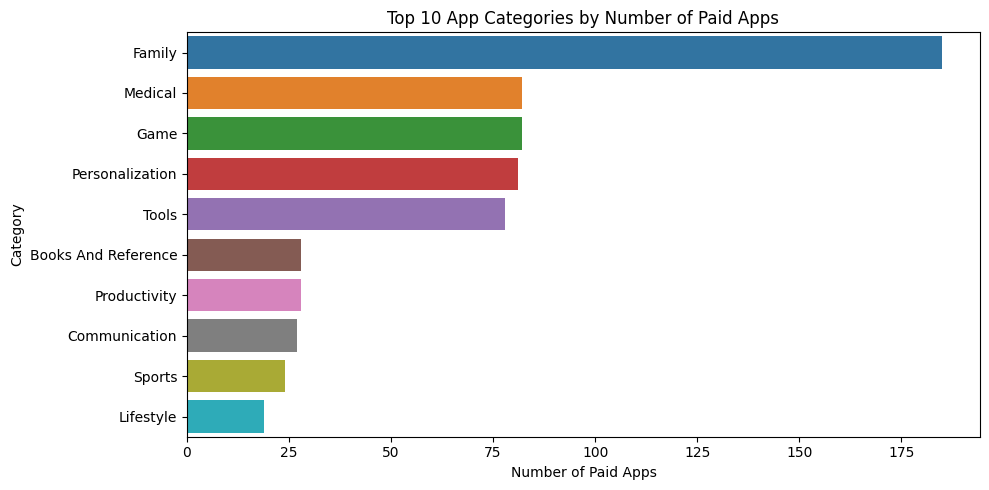

In [21]:
# Filter for Paid apps and count per Category
paid_cat_counts = df[df['Type'] == 'Paid']['Category'].value_counts()

# Compare against total apps in each category to get Paid Share (%)
total_cat_counts = df['Category'].value_counts()
paid_summary = pd.DataFrame({
    'Paid_Apps': paid_cat_counts,
    'Total_Apps': total_cat_counts
}).fillna(0)
paid_summary['Paid_Apps'] = paid_summary['Paid_Apps'].astype(int)
paid_summary['Paid_Share (%)'] = ((paid_summary['Paid_Apps'] / paid_summary['Total_Apps']) * 100).round(2)
paid_summary = paid_summary.sort_values(by='Paid_Apps', ascending=False)

display(paid_summary.head(10))

# Plot Top 10 categories by number of Paid apps
plt.figure(figsize=(10, 5))
sns.barplot(
    x=paid_summary.head(10)['Paid_Apps'],
    y=paid_summary.head(10).index,
    hue=paid_summary.head(10).index,
    legend=False
)
plt.title('Top 10 App Categories by Number of Paid Apps')
plt.xlabel('Number of Paid Apps')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

**Conclusion:** **Family** leads in total paid app volume with **185 paid apps** (9.86% of its catalog), followed by **Medical** (**82 paid apps**), **Game** (**82 paid apps**), **Personalization** (**81 paid apps**), and **Tools** (**78 paid apps**). Proportionally, **Personalization** (**21.54%**) and **Medical** (**20.76%**) stand out with over one-fifth of their apps priced as paid downloads, showing strong user willingness to pay upfront for specialized medical utilities and custom themes/icons.

### Medium Question 9: What is the relationship between reviews and rating?

**Objective:** Measure the correlation between `Reviews` and `Rating` and inspect average ratings across review volume tiers to determine whether apps with more user feedback achieve higher ratings.

Correlation between Reviews and Rating: 0.0552


,Rated_Apps,Mean_Rating,Median_Rating
Review_Tier,,,
0–100,1905,4.09,4.3
101–1K,1488,4.04,4.1
1K–10K,1530,4.14,4.2
10K–100K,1822,4.24,4.3
100K–1M,1101,4.35,4.4
1M+,350,4.43,4.4


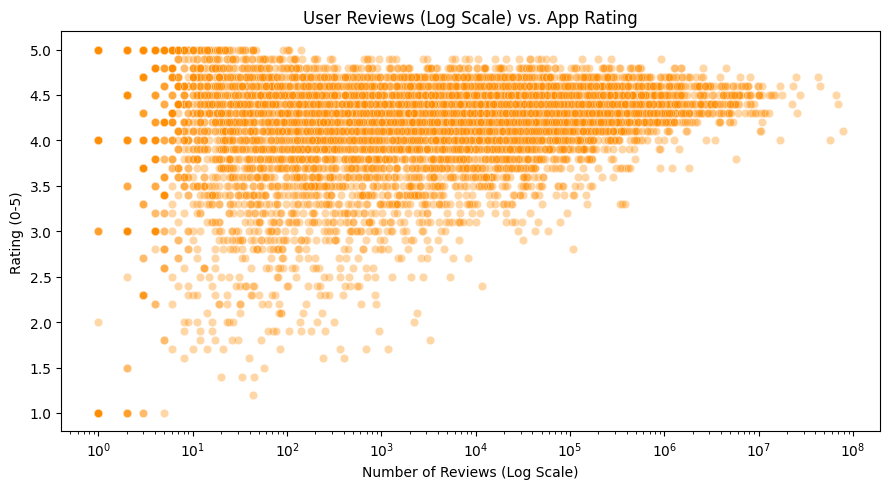

In [22]:
# Calculate Pearson correlation between Reviews and Rating
corr_reviews_rating = df['Reviews'].corr(df['Rating'])
print(f"Correlation between Reviews and Rating: {corr_reviews_rating:.4f}")

# Group apps into review volume tiers to compare average and median ratings
review_bins = [-1, 100, 1000, 10000, 100000, 1000000, df['Reviews'].max()]
review_labels = ['0–100', '101–1K', '1K–10K', '10K–100K', '100K–1M', '1M+']
df['Review_Tier'] = pd.cut(df['Reviews'], bins=review_bins, labels=review_labels)

review_tier_summary = df.groupby('Review_Tier', observed=False)['Rating'].agg(
    Rated_Apps='count',
    Mean_Rating='mean',
    Median_Rating='median'
).round(2)

display(review_tier_summary)

# Scatter plot of Reviews (log scale) vs Rating
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df[df['Reviews'] > 0], x='Reviews', y='Rating', alpha=0.35, color='darkorange')
plt.xscale('log')
plt.title('User Reviews (Log Scale) vs. App Rating')
plt.xlabel('Number of Reviews (Log Scale)')
plt.ylabel('Rating (0-5)')
plt.tight_layout()
plt.show()

**Conclusion:** The overall linear correlation between `Reviews` and `Rating` is **0.0552** (very weak due to extreme outliers with millions of reviews), but grouping apps into review volume tiers reveals a clear positive progression: average ratings climb steadily from **4.04** (101–1K reviews) up to **4.35** (100K–1M reviews) and **4.43** for apps with **1M+ reviews**. Apps that build large, engaged user bases consistently maintain higher user satisfaction.

### Medium Question 10: How many apps have not been updated since 2015?

**Objective:** Count apps whose `Last Updated` year is 2015 or earlier (`<= 2015`) to measure the share of outdated or abandoned apps on the platform.

In [24]:
# Filter apps last updated in or before 2015
outdated_apps = df[df['Last Updated'].dt.year <= 2015]
outdated_count = len(outdated_apps)
outdated_pct = (outdated_count / len(df)) * 100

print(f"Apps not updated since 2015 (<= 2015): {outdated_count} out of {len(df)} apps ({outdated_pct:.2f}%)")

# Breakdown by year up to 2015
display(outdated_apps['Last Updated'].dt.year.value_counts().sort_index().to_frame(name='Apps_Count'))

Apps not updated since 2015 (<= 2015): 801 out of 9659 apps (8.29%)


,Apps_Count
Last Updated,
2010,1
2011,15
2012,26
2013,108
2014,203
2015,448


**Conclusion:** A total of **801 apps (8.29%)** have not been updated since **2015** (`<= 2015`), with the largest share coming from **2015 (448 apps)** and **2014 (203 apps)**. While over 91% of the store's catalog was updated between 2016 and 2018, this 8.29% represents legacy or abandoned listings that lack modern Android OS support and security updates.